In [9]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
from collections import Counter, defaultdict
import json
import random
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Libraries imported successfully.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Libraries imported successfully.


In [10]:
PROJECT_DIR = Path("/content/drive/MyDrive/deeplearning")
DATASET_DIR = PROJECT_DIR / "Dataset" / "Dataset_for_yolo"
RESULTS_DIR = PROJECT_DIR / "results"
PLOTS_DIR = RESULTS_DIR / "plots"
METRICS_DIR = RESULTS_DIR / "metrics"

PLOTS_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

report_path = RESULTS_DIR / "dataset_setup_report.json"

if not DATASET_DIR.exists():
    raise FileNotFoundError(f"Dataset not found: {DATASET_DIR}")

yaml_candidates = sorted(DATASET_DIR.rglob("data.yaml"))
yaml_candidates += sorted(DATASET_DIR.rglob("data.yml"))

if not yaml_candidates:
    raise FileNotFoundError("Could not find data.yaml in the dataset folder.")

# Prefer the YAML file in the dataset root.
DATA_YAML = next(
    (p for p in yaml_candidates if p.parent == DATASET_DIR),
    yaml_candidates[0]
)

with open(DATA_YAML, "r") as f:
    dataset_config = yaml.safe_load(f)

print("Dataset:", DATASET_DIR)
print("Configuration:", DATA_YAML)
print("Dataset config:", dataset_config)

Dataset: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo
Configuration: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/data.yaml
Dataset config: {'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 1, 'names': ['bottle'], 'roboflow': {'workspace': 'waste-detection-zxduh', 'project': 'flow-9dt9s-ysldg', 'version': 1, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/waste-detection-zxduh/flow-9dt9s-ysldg/dataset/1'}}


In [11]:
def find_split_images(split_names):
    for split_name in split_names:
        candidates = [
            DATASET_DIR / split_name / "images",
            DATASET_DIR.parent / split_name / "images",
        ]

        for candidate in candidates:
            if candidate.is_dir():
                return candidate.resolve()

    return None


split_paths = {
    "train": find_split_images(["train"]),
    "val": find_split_images(["valid", "val"]),
    "test": find_split_images(["test"]),
}

for split, image_dir in split_paths.items():
    print(f"{split}: {image_dir}")
    print("Exists:", image_dir is not None)

    if image_dir is not None:
        count = sum(
            1 for p in image_dir.rglob("*")
            if p.is_file()
            and p.suffix.lower() in {
                ".jpg", ".jpeg", ".png",
                ".bmp", ".webp", ".tif", ".tiff"
            }
        )
        print("Image count:", count)

train: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/train/images
Exists: True
Image count: 4202
val: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/valid/images
Exists: True
Image count: 401
test: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/test/images
Exists: True
Image count: 200


In [12]:
split_label_dirs = {}

for split, image_dir in split_paths.items():
    if image_dir is None:
        continue

    label_dir = image_dir.parent / "labels"
    split_label_dirs[split] = label_dir

    print(f"\n{split}")
    print("Images:", image_dir)
    print("Labels:", label_dir)
    print("Label directory exists:", label_dir.is_dir())


train
Images: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/train/images
Labels: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/train/labels
Label directory exists: True

val
Images: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/valid/images
Labels: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/valid/labels
Label directory exists: True

test
Images: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/test/images
Labels: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/test/labels
Label directory exists: True


In [13]:
# Supported image formats
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

print("IMAGE_EXTENSIONS initialized successfully.")

IMAGE_EXTENSIONS initialized successfully.


In [15]:

from pathlib import Path
from collections import Counter
from PIL import Image
import numpy as np
import pandas as pd
import random

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

records = []
label_errors = []
class_counts = Counter()
image_errors = []

random.seed(42)

for split, image_dir in split_paths.items():
    if image_dir is None or not image_dir.exists():
        print(f"Skipping missing split: {split}")
        continue

    label_dir = split_label_dirs[split]

    print(f"Scanning {split}...", flush=True)

    image_files = [
        p for p in image_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    # Test readability on a representative sample only.
    readability_sample = set(
        random.sample(image_files, min(100, len(image_files)))
    )

    for index, image_path in enumerate(image_files, start=1):
        relative_path = image_path.relative_to(image_dir)
        label_path = (label_dir / relative_path).with_suffix(".txt")

        record = {
            "split": split,
            "image": str(image_path),
            "label": str(label_path),
            "label_exists": label_path.exists(),
            "image_readable": None,
            "objects": 0,
            "valid_annotations": 0,
        }

        if image_path in readability_sample:
            try:
                with Image.open(image_path) as im:
                    im.verify()
                record["image_readable"] = True
            except Exception as exc:
                record["image_readable"] = False
                image_errors.append({
                    "image": str(image_path),
                    "error": str(exc)
                })

        if not label_path.exists():
            label_errors.append({
                "image": str(image_path),
                "error": "Missing label file"
            })
            records.append(record)
            continue

        try:
            with open(label_path, "r") as f:
                for line_number, line in enumerate(f, start=1):
                    if not line.strip():
                        continue

                    record["objects"] += 1

                    try:
                        values = [float(v) for v in line.split()]

                        if len(values) != 5:
                            raise ValueError("Expected 5 values")

                        cls, x, y, w, h = values

                        if not np.isfinite(values).all():
                            raise ValueError("Non-finite value")

                        if not cls.is_integer():
                            raise ValueError("Class ID is not an integer")

                        class_id = int(cls)

                        if not 0 <= class_id < num_classes:
                            raise ValueError("Invalid class ID")

                        if not all(0 <= v <= 1 for v in [x, y, w, h]):
                            raise ValueError("Coordinates outside [0, 1]")

                        if w <= 0 or h <= 0:
                            raise ValueError("Non-positive box dimensions")

                        record["valid_annotations"] += 1
                        class_counts[class_id] += 1

                    except Exception as exc:
                        label_errors.append({
                            "image": str(image_path),
                            "label": str(label_path),
                            "line": line_number,
                            "error": str(exc)
                        })

        except Exception as exc:
            label_errors.append({
                "image": str(image_path),
                "label": str(label_path),
                "error": f"Could not read label: {exc}"
            })

        records.append(record)

        if index % 500 == 0:
            print(f"  Processed {index}/{len(image_files)} images",
                  flush=True)

inspection_df = pd.DataFrame(records)

print("\nInspection complete.")
print("Images scanned:", len(inspection_df))
print("Label errors:", len(label_errors))
print("Image errors in readability sample:", len(image_errors))
print("Valid bounding boxes:", int(
    inspection_df["valid_annotations"].sum()
))


Scanning train...
  Processed 500/4202 images
  Processed 1000/4202 images
  Processed 1500/4202 images
  Processed 2000/4202 images
  Processed 2500/4202 images
  Processed 3000/4202 images
  Processed 3500/4202 images
  Processed 4000/4202 images
Scanning val...
Scanning test...

Inspection complete.
Images scanned: 4803
Label errors: 12709
Image errors in readability sample: 0
Valid bounding boxes: 0


In [18]:
import yaml
from pathlib import Path

with open(DATA_YAML, "r") as f:
    dataset_config = yaml.safe_load(f)

names = dataset_config["names"]

if isinstance(names, dict):
    class_names = [
        names[k] for k in sorted(names, key=lambda x: int(x))
    ]
else:
    class_names = list(names)

num_classes = len(class_names)

print("Class names:", class_names)
print("Number of classes:", num_classes)

Class names: ['bottle']
Number of classes: 1


In [19]:
summary = (
    inspection_df.groupby("split")
    .agg(
        images=("image", "count"),
        readable_images=("image_readable", "sum"),
        images_with_label_files=("label_exists", "sum"),
        annotated_objects=("valid_annotations", "sum"),
    )
    .reset_index()
)

summary["unreadable_images"] = (
    summary["images"] - summary["readable_images"]
)
summary["missing_label_files"] = (
    summary["images"] - summary["images_with_label_files"]
)

print("Dataset health summary:")
display(summary)

print("\nClass distribution:")

class_summary = pd.DataFrame({
    "class_id": list(range(num_classes)),
    "class_name": class_names,
    "total_objects": [
        class_counts.get(i, 0) for i in range(num_classes)
    ],
})

display(class_summary)
summary.to_csv(
    METRICS_DIR / "dataset_health_summary.csv",
    index=False
)

class_summary.to_csv(
    METRICS_DIR / "class_distribution.csv",
    index=False
)

pd.DataFrame(label_errors).to_csv(
    METRICS_DIR / "label_validation_errors.csv",
    index=False
)

pd.DataFrame(image_errors).to_csv(
    METRICS_DIR / "image_read_errors.csv",
    index=False
)

print("Reports saved to:", METRICS_DIR)

Dataset health summary:


,split,images,readable_images,images_with_label_files,annotated_objects,unreadable_images,missing_label_files
0,test,200,100,200,0,100,0
1,train,4202,100,4200,0,4102,2
2,val,401,100,400,0,301,1



Class distribution:


,class_id,class_name,total_objects
0,0,bottle,0


Reports saved to: /content/drive/MyDrive/deeplearning/results/metrics


In [20]:
def load_valid_boxes(label_path):
    boxes = []

    if not label_path.exists():
        return boxes

    for line in label_path.read_text().splitlines():
        if not line.strip():
            continue

        try:
            values = [float(v) for v in line.split()]

            if len(values) != 5:
                continue

            cls, x, y, w, h = values
            class_id = int(cls)

            if (
                cls != class_id
                or not 0 <= class_id < num_classes
                or not np.isfinite(values).all()
                or not all(0 <= v <= 1 for v in [x, y, w, h])
                or w <= 0 or h <= 0
            ):
                continue

            boxes.append((class_id, x, y, w, h))

        except (ValueError, TypeError):
            continue

    return boxes


def visualize_sample(row):
    image_path = Path(row["image"])
    label_path = Path(row["label"])

    with Image.open(image_path) as im:
        image = im.convert("RGB")

    draw = ImageDraw.Draw(image)
    width, height = image.size

    for class_id, x, y, w, h in load_valid_boxes(label_path):
        x1 = int((x - w / 2) * width)
        y1 = int((y - h / 2) * height)
        x2 = int((x + w / 2) * width)
        y2 = int((y + h / 2) * height)

        draw.rectangle((x1, y1, x2, y2), outline="red", width=3)
        draw.text(
            (max(0, x1), max(0, y1 - 14)),
            class_names[class_id],
            fill="yellow",
            stroke_width=1,
            stroke_fill="black",
        )

    return image


readable = inspection_df[
    (inspection_df["image_readable"] == True)
    & (inspection_df["label_exists"] == True)
]

if len(readable) == 0:
    print("No readable images with label files were found.")
else:
    samples = readable.sample(
        n=min(8, len(readable)),
        random_state=SEED
    )

    fig, axes = plt.subplots(2, 4, figsize=(18, 9))
    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, samples.iterrows()):
        ax.imshow(visualize_sample(row))
        ax.set_title(
            f"{row['split']} | {Path(row['image']).name}",
            fontsize=9
        )
        ax.axis("off")

    plt.tight_layout()

    figure_path = PLOTS_DIR / "dataset_bbox_samples.png"
    plt.savefig(figure_path, dpi=150, bbox_inches="tight")
    plt.show()

    print("Visualization saved to:", figure_path)

Output hidden; open in https://colab.research.google.com to view.

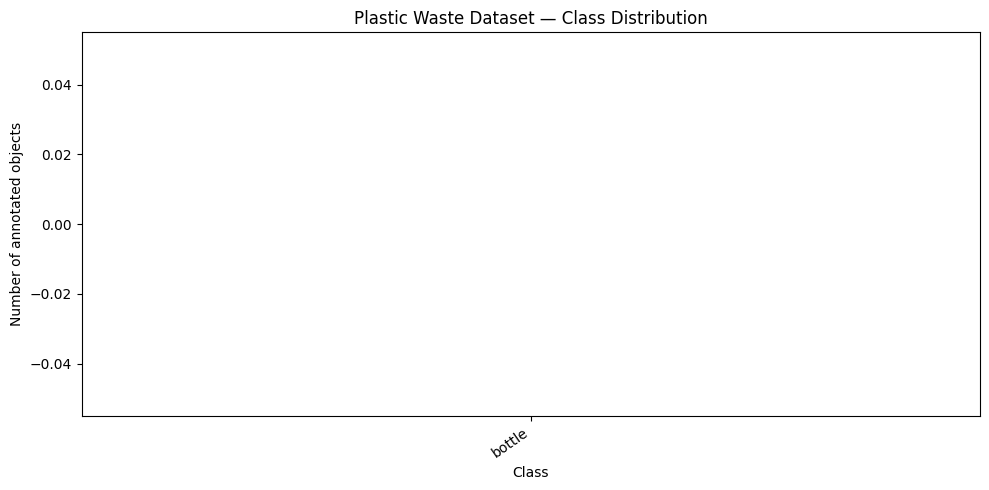

Class distribution plot saved to: /content/drive/MyDrive/deeplearning/results/plots/class_distribution.png


In [21]:
plt.figure(figsize=(10, 5))

plt.bar(
    class_summary["class_name"],
    class_summary["total_objects"]
)

plt.title("Plastic Waste Dataset — Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of annotated objects")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

class_plot_path = PLOTS_DIR / "class_distribution.png"
plt.savefig(class_plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("Class distribution plot saved to:", class_plot_path)

,count,mean,std,min,25%,50%,75%,max
class_name,,,,,,,,
bottle,723.0,0.0029,0.00573,0.00003,0.00044,0.00093,0.0024,0.05247


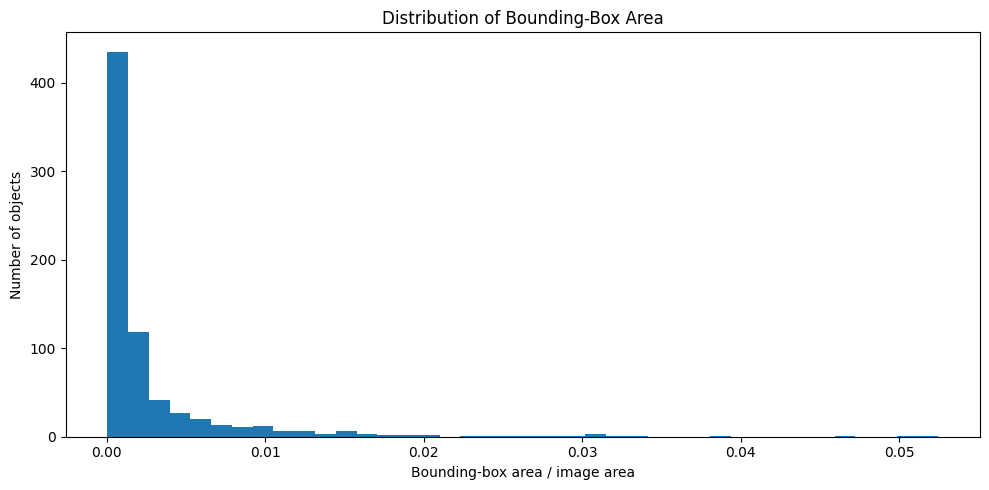

Object-size plot saved to: /content/drive/MyDrive/deeplearning/results/plots/bbox_area_distribution.png


In [22]:
area_records = []

for _, row in inspection_df.iterrows():
    label_path = Path(row["label"])

    if not row["image_readable"] or not row["label_exists"]:
        continue

    for class_id, x, y, w, h in load_valid_boxes(label_path):
        area_records.append({
            "split": row["split"],
            "class_id": class_id,
            "class_name": class_names[class_id],
            "box_width_fraction": w,
            "box_height_fraction": h,
            "box_area_fraction": w * h,
        })

area_df = pd.DataFrame(area_records)

if area_df.empty:
    print("No valid bounding boxes available for size analysis.")
else:
    display(
        area_df.groupby("class_name")["box_area_fraction"]
        .describe()
        .round(5)
    )

    plt.figure(figsize=(10, 5))
    plt.hist(
        area_df["box_area_fraction"],
        bins=40
    )
    plt.title("Distribution of Bounding-Box Area")
    plt.xlabel("Bounding-box area / image area")
    plt.ylabel("Number of objects")
    plt.tight_layout()

    size_plot_path = PLOTS_DIR / "bbox_area_distribution.png"
    plt.savefig(size_plot_path, dpi=150, bbox_inches="tight")
    plt.show()

    print("Object-size plot saved to:", size_plot_path)

In [23]:
total_images = len(inspection_df)
unreadable_count = len(image_errors)
label_issue_count = len(label_errors)
missing_label_count = int((~inspection_df["label_exists"]).sum())

valid_box_count = int(inspection_df["valid_annotations"].sum())

missing_train = (
    "train" not in split_paths
    or split_paths["train"] is None
    or not split_paths["train"].exists()
)

missing_val = (
    "val" not in split_paths
    or split_paths["val"] is None
    or not split_paths["val"].exists()
)

status = {
    "total_images_inspected": total_images,
    "unreadable_images": unreadable_count,
    "missing_label_files": missing_label_count,
    "annotation_errors": label_issue_count,
    "valid_bounding_boxes": valid_box_count,
    "training_split_found": not missing_train,
    "validation_split_found": not missing_val,
    "ready_for_manual_review": (
        not missing_train
        and not missing_val
        and unreadable_count == 0
        and label_issue_count == 0
        and missing_label_count == 0
        and valid_box_count > 0
    ),
}

print("FINAL DATASET INSPECTION")
print("=" * 35)

for key, value in status.items():
    print(f"{key}: {value}")

with open(METRICS_DIR / "dataset_inspection_status.json", "w") as f:
    json.dump(status, f, indent=4)

print("\nInspection results saved to:", METRICS_DIR)

FINAL DATASET INSPECTION
total_images_inspected: 4803
unreadable_images: 0
missing_label_files: 3
annotation_errors: 12709
valid_bounding_boxes: 0
training_split_found: True
validation_split_found: True
ready_for_manual_review: False

Inspection results saved to: /content/drive/MyDrive/deeplearning/results/metrics


In [24]:
from pathlib import Path

for split, image_dir in split_paths.items():
    if image_dir is None or not image_dir.exists():
        continue

    label_dir = image_dir.parent / "labels"

    print(f"\n{'='*45}")
    print("Split:", split)
    print("Image directory:", image_dir)
    print("Label directory:", label_dir)
    print("Label directory exists:", label_dir.exists())

    if not label_dir.exists():
        continue

    label_files = sorted(label_dir.rglob("*.txt"))
    print("Total label files:", len(label_files))

    nonempty = 0

    for label_file in label_files:
        content = label_file.read_text().strip()

        if content:
            nonempty += 1

            if nonempty <= 3:
                print("\nFile:", label_file.name)
                print("Contents:", repr(content[:300]))

    print("Non-empty label files:", nonempty)


Split: train
Image directory: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/train/images
Label directory: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/train/labels
Label directory exists: True
Total label files: 4202

File: 000001_jpg.rf.0ce6f12392f8a74e594ff4e532807dd1.txt
Contents: '0 0.334375 0.43984375 0.03515625 0.0484375'

File: 000001_jpg.rf.350e6dcd991cbaf3b3028a52dcd290b1.txt
Contents: '0 0.34921875 0.409375 0.04375 0.0546875'

File: 000001_jpg.rf.5a2ff0c31ef76ec8269e07e26b7e01a4.txt
Contents: '0 0.32578125 0.47578125 0.04375 0.0546875'
Non-empty label files: 4202

Split: val
Image directory: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/valid/images
Label directory: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/valid/labels
Label directory exists: True
Total label files: 400

File: 000368_jpg.rf.1afebc8e48cd52a6a4fb7aff2408ba7d.txt
Contents: '0 0.340625 0.59609375 0.02421875 0.0421875\n0 0.540625 0.58125 0.04296875